# Analiza z uwzględnieniem trendów (2013–2023)

Rozszerzenie `01_analiza_glowna.ipynb`: każdy stan opisujemy nie tylko **średnią** z lat 2013–2023, ale też **trendem** (nachylenie prostej regresji w czasie, jednostka zmiennej na rok). Pozwala to odróżnić stany, które są podobne dziś, ale zmieniają się w różnych kierunkach.

Poprawka względem wersji kursowej: nachylenie jest liczone względem faktycznego roku, więc przerwa 2019→2021 (brak 2020) to 2 lata, a nie 1.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import linregress
from sklearn.metrics import silhouette_score

from ushealth.data import CLUSTER_COLS, ID_COLS, label, load_panel
from ushealth import clustering as cl
from ushealth import plots

plots.setup()
panel = load_panel()

## 1. Cechy: średnia i trend per stan

In [2]:
def mean_and_trend(group: pd.DataFrame) -> pd.Series:
    group = group.sort_values("Year")
    row = {}
    for col in CLUSTER_COLS:
        # HighActivity is measured only in odd years: fill the gaps linearly
        y = group[col].interpolate(limit_direction="both").to_numpy(dtype=float)
        row[f"{col}_mean"] = y.mean()
        row[f"{col}_trend"] = linregress(group["Year"], y).slope
    return pd.Series(row)

states = panel.groupby(ID_COLS).apply(mean_and_trend).reset_index()
print(f"Stany: {len(states)}, cechy: {states.shape[1] - len(ID_COLS)}, braki: {states.isna().sum().sum()}")

Stany: 50, cechy: 24, braki: 0


Usuwamy trend temperatury (szum pogodowy, a nie zmiana strukturalna) i trend odsetka bezrobotnych (odzwierciedla głównie cykl koniunkturalny i COVID, wspólny dla wszystkich stanów).

In [3]:
FEATURES = [c for c in states.columns if c not in ID_COLS and c not in ("avg_temp_trend", "pct_bezrobotni_trend")]
print(len(FEATURES), "cech")

22 cech


## 2. PCA

PC1: 37.3%, PC2: 15.5%, PC1+PC2: 52.8%


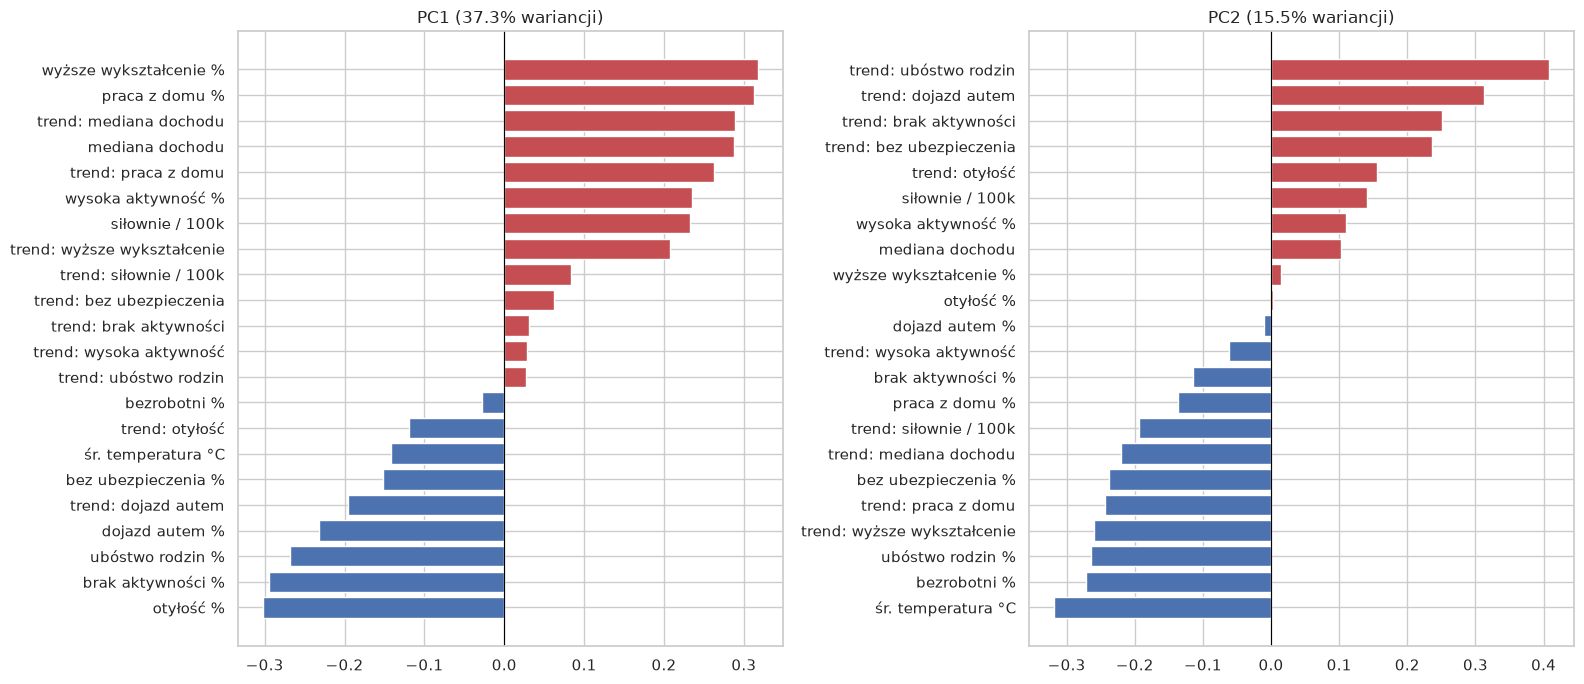

In [4]:
X_raw = states[FEATURES].values
X_scaled, X_pca, pca = cl.fit_pca(X_raw)
X2 = X_pca[:, :2]
explained = pca.explained_variance_ratio_
print(f"PC1: {explained[0]:.1%}, PC2: {explained[1]:.1%}, PC1+PC2: {explained[:2].sum():.1%}")

loadings = pd.DataFrame(pca.components_[:2].T, index=[label(c) for c in FEATURES], columns=["PC1", "PC2"])
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, pc, ev in zip(axes, ["PC1", "PC2"], explained):
    s = loadings[pc].sort_values()
    ax.barh(s.index, s.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in s])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_title(f"{pc} ({ev:.1%} wariancji)")
plt.tight_layout()
plots.save(fig, "trend_pca_loadings")
plt.show()

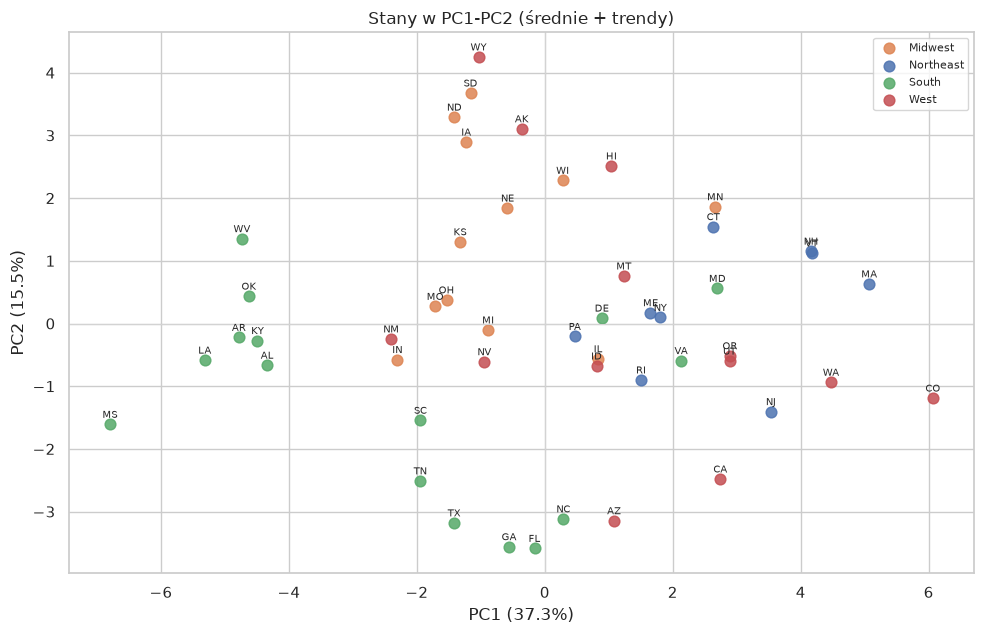

In [5]:
fig = plots.pca_scatter(states, X2, explained, states["Region"], plots.REGION_PALETTE, "Stany w PC1-PC2 (średnie + trendy)")
plots.save(fig, "trend_pca_regions")
plt.show()

PC1 nadal jest osią zamożności i zdrowia, ale wchodzą do niej też trendy (np. wzrost pracy z domu i dochodów w bogatszych stanach). PC2 zbiera trendy: rosnące ubóstwo i brak aktywności po jednej stronie, poprawę po drugiej. PC1+PC2 wyjaśniają wyraźnie mniej wariancji niż w analizie samych średnich, więc rzut na 2 wymiary traci więcej informacji.

## 3. Klasteryzacja (PC1–PC2)

Ward k=4 i K-Means k=5 jak w notebooku 01. GMM pominięty: model z pełną kowariancją przy 50 stanach (ok. 30 parametrów) daje zdegenerowane rozwiązania, np. klaster z jednym stanem.

In [6]:
solutions = {
    "Ward k=4": cl.hierarchical(X2, 4),
    "K-Means k=5": cl.kmeans(X2, 5),
}
names = {m: cl.cluster_names(states, lab, FEATURES, suffix="_mean") for m, lab in solutions.items()}

summary = pd.DataFrame({m: cl.scores(X2, lab) for m, lab in solutions.items()}).T
summary["silhouette_12d"] = [silhouette_score(X_scaled, lab) for lab in solutions.values()]
summary.round(3)

,silhouette,davies_bouldin,n_clusters,silhouette_12d
Ward k=4,0.457,0.739,4.0,0.162
K-Means k=5,0.452,0.694,5.0,0.134


In [7]:
for method, nm in names.items():
    print(method)
    for name, grp in states.groupby(nm):
        print(f"  {name} ({len(grp)}): {', '.join(grp['LocationAbbr'])}")
print()
print(cl.agreement(solutions))

Ward k=4
  R1: brak aktywności ↑, ubóstwo rodzin ↑ (7): AL, AR, KY, LA, MS, OK, WV
  R2: trend: ubóstwo rodzin ↓, bez ubezpieczenia ↑ (13): AZ, FL, GA, IN, MI, MO, NV, NM, NC, OH, SC, TN, TX
  R3: trend: dojazd autem ↑, trend: praca z domu ↓ (9): AK, HI, IA, KS, NE, ND, SD, WI, WY
  R4: wyższe wykształcenie ↑, praca z domu ↑ (21): CA, CO, CT, DE, ID, IL, ME, MD, MA, MN, MT, NH, NJ, NY, OR, PA, RI, UT, VT, VA, WA
K-Means k=5
  R1: brak aktywności ↑, ubóstwo rodzin ↑ (7): AL, AR, KY, LA, MS, OK, WV
  R2: bez ubezpieczenia ↑, trend: ubóstwo rodzin ↓ (6): AZ, FL, GA, NC, TN, TX
  R3: mediana dochodu ↓, siłownie / 100k ↓ (12): DE, ID, IL, IN, KS, MI, MO, NV, NM, OH, PA, SC
  R4: trend: dojazd autem ↑, trend: praca z domu ↓ (8): AK, HI, IA, NE, ND, SD, WI, WY
  R5: wyższe wykształcenie ↑, praca z domu ↑ (17): CA, CO, CT, ME, MD, MA, MN, MT, NH, NJ, NY, OR, RI, UT, VT, VA, WA

             Ward k=4  K-Means k=5
Ward k=4         1.00         0.66
K-Means k=5      0.66         1.00


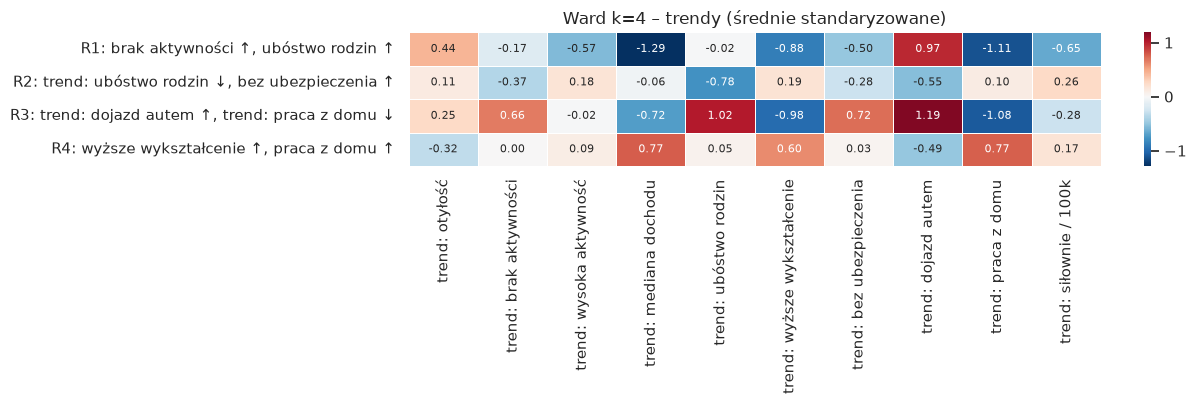

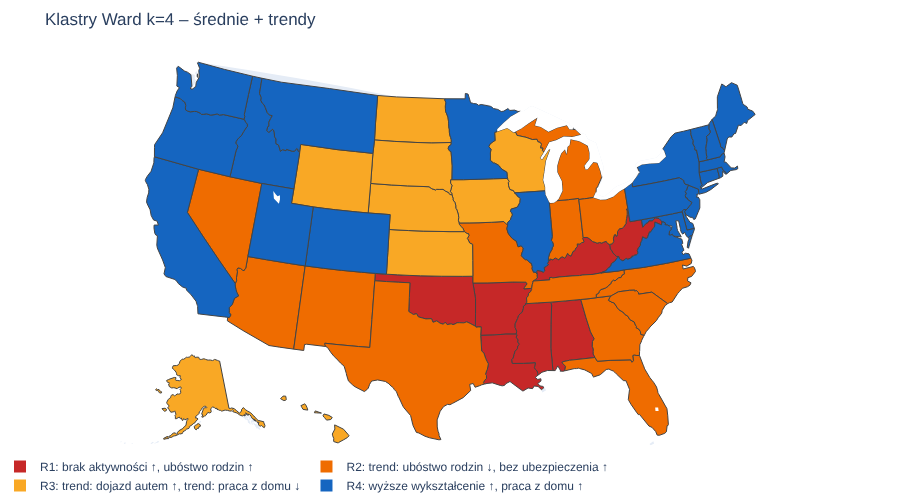

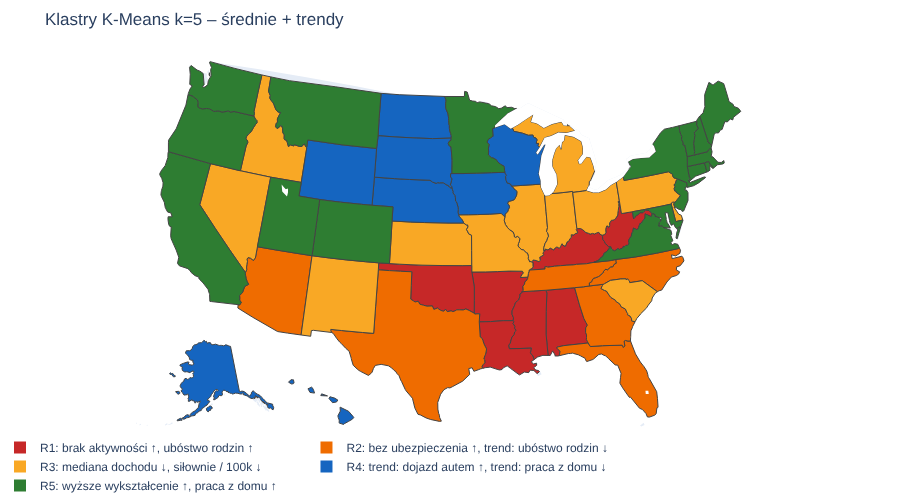

In [8]:
TREND_COLS = [c for c in FEATURES if c.endswith("_trend")]
fig = plots.profile_heatmap(states, names["Ward k=4"], TREND_COLS, "Ward k=4 – trendy (średnie standaryzowane)")
plots.save(fig, "trend_profiles_ward")
plt.show()
for method in ["Ward k=4", "K-Means k=5"]:
    fig = plots.cluster_map(states, names[method], f"Klastry {method} – średnie + trendy")
    plots.save(fig, f"trend_map_{method.split()[0].lower().replace('-', '')}")
    fig.show()

## 4. Wnioski

- **Rdzeń wysokiego ryzyka (R1) się nie zmienia:** te same 7 stanów co w notebooku 01.
- **R2 (Sun Belt i przemysłowy Midwest) nadrabia:** najszybszy spadek ubóstwa rodzin (−0,35 pp/rok vs −0,25 średnio) i braku aktywności, ale wciąż najwięcej nieubezpieczonych.
- **R3 (AK, HI, IA, KS, NE, ND, SD, WI, WY) poprawia się najwolniej:** ubóstwo spada ok. 2× wolniej niż średnio, brak aktywności nie spada wcale, dojazd autem spada najwolniej, a praca z domu rośnie najwolniej. To względne pogarszanie się na tle reszty kraju, a nie bezwzględny spadek – w wersji kursowej było to opisane jako „pogarszająca się sytuacja”.
- **R4 (zamożne stany) odjeżdża:** najszybszy wzrost dochodu (ok. 2,8 tys. USD/rok vs 2,4 tys. średnio) i pracy z domu, najwolniejszy wzrost otyłości.
- **Otyłość rośnie we wszystkich grupach** (0,5–0,6 pp rocznie).

Struktura jest jeszcze słabsza niż w analizie samych średnich: PC1+PC2 obejmują ok. 53% wariancji, a silhouette w pełnej przestrzeni to 0,13–0,16. Trendy z 10 punktów na stan, liczone z estymat obciążonych błędem próby, są zaszumione – ten notebook traktujemy jako eksploracyjny.